In [1]:
%load_ext autoreload
%autoreload 2

import cv2
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm.auto import tqdm

/data/projects/personal/meles/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
RESULTS_PATH = Path("../../results/collect/structure.parquet")
RESULTS = pd.read_parquet(RESULTS_PATH)
RESULTS

,top-1,top-5,top-10,frame-top-1,fold,frame_anonymization_method,frame_embedding_method,video_aggregation_method,video_embedding_method,identity_aggregation_method,pipeline
0,0.930171,0.959157,0.961792,0.897632,1,none,sface,none,None,none,frame
1,0.951014,0.969595,0.974662,0.909659,2,none,sface,none,None,none,frame
2,0.935305,0.959335,0.968577,0.899965,3,none,sface,none,None,none,frame
3,0.928854,0.957839,0.971014,0.907681,1,none,sface,none,None,pooling_mean,frame
4,0.947635,0.972973,0.979730,0.918251,2,none,sface,none,None,pooling_mean,frame
...,...,...,...,...,...,...,...,...,...,...,...
571,0.168919,0.283784,0.356419,0.168919,2,pixelation,arcface,normweighted,None,consensus_beta1,frame
572,0.160813,0.284658,0.341959,0.160813,3,pixelation,arcface,normweighted,None,consensus_beta1,frame
573,0.152833,0.266140,0.354414,0.152833,1,pixelation,arcface,normweighted,None,normweighted,frame
574,0.170608,0.290541,0.351351,0.170608,2,pixelation,arcface,normweighted,None,normweighted,frame


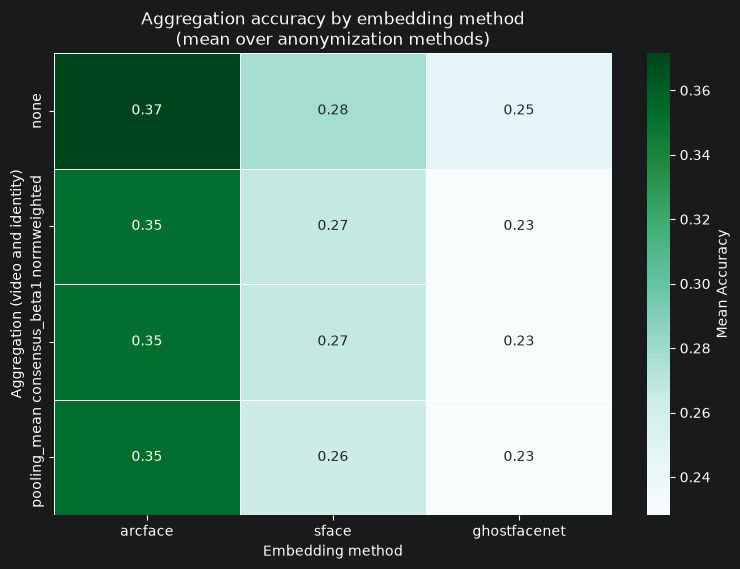

In [3]:
# Select all rows where the same aggregation method is used for both the video and identity. This collapses one dimension and simulates the previous results.
results = RESULTS[(RESULTS["identity_aggregation_method"] == RESULTS["video_aggregation_method"]) & (RESULTS["frame_anonymization_method"] != "none")]

agg_order = (
    results.groupby("identity_aggregation_method")["top-1"].mean().sort_values(ascending=False).index
)
embedding_order = (
    results.groupby("frame_embedding_method")["top-1"].mean().sort_values(ascending=False).index
)

# Pivot `results`, not RESULTS: pivoting RESULTS averages over all nine video/identity
# combinations and silently undoes the filter above.
pivot_agg_embed = results.pivot_table(
    index="video_aggregation_method", columns="frame_embedding_method", values="top-1", aggfunc="mean"
).loc[agg_order, embedding_order]

plt.figure(figsize=(9, 6))
sns.heatmap(pivot_agg_embed, annot=True, fmt=".2f", cmap="BuGn", cbar_kws={"label": "Mean Accuracy"}, linewidths=0.5, linecolor="w")

plt.title("Aggregation accuracy by embedding method\n(mean over anonymization methods)")
plt.xlabel("Embedding method")
plt.ylabel("Aggregation (video and identity)")
plt.show()

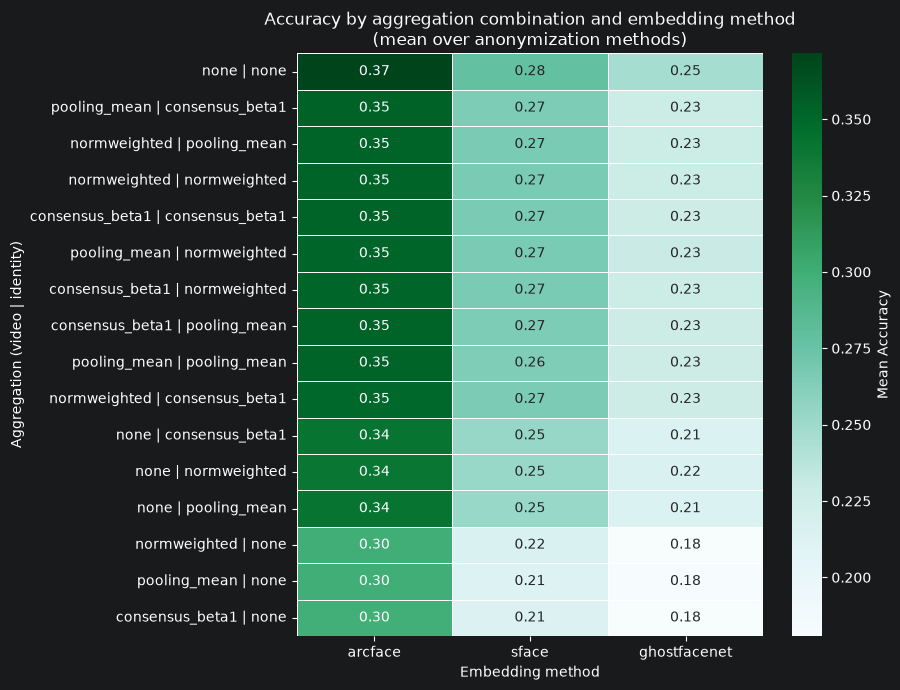

In [4]:
# Label every row with its full (video | identity) aggregation combination, so the mixed
# combinations stay visible instead of collapsing onto the matched ones.
#
# Derive from RESULTS, not from `results`: `results` is the matched-only subset built in the cell
# above (108 of 324 rows), so it only ever contains the three "X | X" combinations. That is what
# was dropping entries here.
results = RESULTS[(RESULTS["frame_anonymization_method"] != "none")]
combinations = results.assign(
    aggregation_method=results["video_aggregation_method"] + " | " + results["identity_aggregation_method"]
)

agg_order = (
    combinations.groupby("aggregation_method")["top-1"].mean().sort_values(ascending=False).index
)
embedding_order = (
    combinations.groupby("frame_embedding_method")["top-1"].mean().sort_values(ascending=False).index
)

pivot_agg_embed = combinations.pivot_table(
    index="aggregation_method", columns="frame_embedding_method", values="top-1", aggfunc="mean"
).loc[agg_order, embedding_order]

plt.figure(figsize=(9, 7))
sns.heatmap(pivot_agg_embed, annot=True, fmt=".2f", cmap="BuGn", cbar_kws={"label": "Mean Accuracy"}, linewidths=0.5, linecolor="w")

plt.title("Accuracy by aggregation combination and embedding method\n(mean over anonymization methods)")
plt.xlabel("Embedding method")
plt.ylabel("Aggregation (video | identity)")
plt.tight_layout()
plt.show()

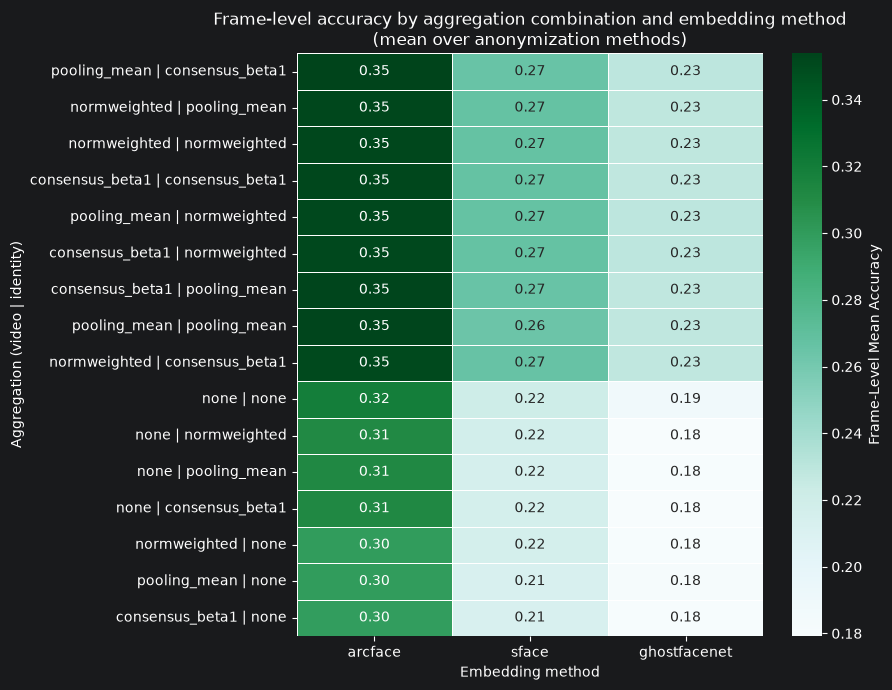

In [5]:
# Label every row with its full (video | identity) aggregation combination, so the mixed
# combinations stay visible instead of collapsing onto the matched ones.
#
# Derive from RESULTS, not from `results`: `results` is the matched-only subset built in the cell
# above (108 of 324 rows), so it only ever contains the three "X | X" combinations. That is what
# was dropping entries here.
results = RESULTS[(RESULTS["frame_anonymization_method"] != "none")]
combinations = results.assign(
    aggregation_method=results["video_aggregation_method"] + " | " + results["identity_aggregation_method"]
)

agg_order = (
    combinations.groupby("aggregation_method")["frame-top-1"].mean().sort_values(ascending=False).index
)
embedding_order = (
    combinations.groupby("frame_embedding_method")["frame-top-1"].mean().sort_values(ascending=False).index
)

pivot_agg_embed = combinations.pivot_table(
    index="aggregation_method", columns="frame_embedding_method", values="frame-top-1", aggfunc="mean"
).loc[agg_order, embedding_order]

plt.figure(figsize=(9, 7))
sns.heatmap(pivot_agg_embed, annot=True, fmt=".2f", cmap="BuGn", cbar_kws={"label": "Frame-Level Mean Accuracy"}, linewidths=0.5, linecolor="w")

plt.title("Frame-level accuracy by aggregation combination and embedding method\n(mean over anonymization methods)")
plt.xlabel("Embedding method")
plt.ylabel("Aggregation (video | identity)")
plt.tight_layout()
plt.show()